In [1]:
%pip install pandas requests matplotlib

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
import re

from datetime import datetime, timedelta, timezone

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
GAMES = {
    "Cyberpunk 2077": 1091500,
    "No Man's Sky": 275850,
    "Helldivers 2": 553850,
    "Elden Ring": 1245620
}

GAME = "Cyberpunk 2077"
APP_ID = GAMES[GAME]

WINDOW_DAYS = 14

print(f"Selected game: {GAME}")
print(f"Steam App ID: {APP_ID}")

Selected game: Cyberpunk 2077
Steam App ID: 1091500


In [3]:
# Collect update news that looks patch related

NEWS_URL = "https://api.steampowered.com/ISteamNews/GetNewsForApp/v2/"
REVIEWS_URL = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"

session = requests.Session()

# returns json format of requested url api request
def get_json(url, params):
    for attempt in range(4):
        response = session.get(url, params=params, timeout=30)

        if response.status_code in [429, 500, 502, 503, 504]:
            if attempt == 3:
                response.raise_for_status()

            wait = min(60, 5 * (2 ** attempt))
            time.sleep(wait)
            continue

        response.raise_for_status()
        return response.json()


#scrapes the pages for news, finds update/patch related announcements
def get_patch_news(app_id, max_pages=3):
    news = []
    enddate = None

    for page in range(max_pages):
        params = {
            "appid": app_id,
            "count": 100,
            "maxlength": 1000
        }

        if enddate is not None:
            params["enddate"] = enddate

        data = get_json(NEWS_URL, params)
        batch = data.get("appnews", {}).get("newsitems", [])

        if not batch:
            break

        news.extend(batch)
        enddate = min(item["date"] for item in batch) - 1

        time.sleep(1.5)

    df = pd.DataFrame(news)

    if df.empty:
        return df

    df = df.drop_duplicates(subset="gid")

    df["date"] = pd.to_datetime(
        df["date"], unit="s", utc=True
    )

    # Find announcements that might be patches
    pattern = r"\b(patch|hotfix|update|fixes|changelog)\b"

    df["is_patch_candidate"] = df["title"].str.contains(
        pattern, case=False, regex=True, na=False
    )

    return df.sort_values("date", ascending=False)

In [4]:
patches_df = get_patch_news(APP_ID)

patch_candidates = patches_df[
    patches_df["is_patch_candidate"]
]

display(patch_candidates[["date", "title", "url"]].head(25))

patches_df.to_csv("cyberpunk_news.csv", index=False)

/tmp/ipykernel_1446914/277562373.py:61: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


,date,title,url
29,2026-10-22 10:12:54+00:00,Cyberpunk 2077 Edgerunners update brings impro...,https://steamstore-a.akamaihd.net/news/externa...
30,2026-10-22 10:06:54+00:00,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,https://steamstore-a.akamaihd.net/news/externa...
33,2026-10-21 16:09:58+00:00,Cyberpunk 2077's Edgerunners 2 update adds two...,https://steamstore-a.akamaihd.net/news/externa...
37,2026-10-21 15:45:15+00:00,Check out what's coming to Cyberpunk 2077 in t...,https://steamstore-a.akamaihd.net/news/externa...
43,2026-10-20 10:00:33+00:00,REDstreams — Cyberpunk 2077: Edgerunners 2 Upd...,https://steamstore-a.akamaihd.net/news/externa...
147,2025-09-11 14:58:15+00:00,CDPR returns to the fridge for one more Cyberp...,https://steamstore-a.akamaihd.net/news/externa...
148,2025-09-11 10:09:03+00:00,Patch 2.31,https://steamstore-a.akamaihd.net/news/externa...
161,2025-07-16 17:52:27+00:00,Seven months after putting Johnny Silverhand i...,https://steamstore-a.akamaihd.net/news/externa...
162,2025-07-16 16:12:59+00:00,Cyberpunk 2077 update 2.3 motors into your lif...,https://steamstore-a.akamaihd.net/news/externa...
163,2025-07-16 16:12:38+00:00,Update 2.3 Patch Notes,https://steamstore-a.akamaihd.net/news/externa...


In [5]:
# Collect steam reviews within a start and end date
def get_reviews(app_id, start_date, end_date,
                max_pages=3, language="english"):

    reviews = []
    cursor = "*"
    seen_cursors = set()
    page = 0

    start_ts = int(pd.Timestamp(start_date).timestamp())
    end_ts = int(pd.Timestamp(end_date).timestamp())

    while max_pages is None or page < max_pages:

        if cursor in seen_cursors:
            break

        seen_cursors.add(cursor)

        query = {
            "appid": app_id,
            "filter": 1,              # Newest created first
            "languages": [language],
            "review_type": 0,         # Positive and negative
            "purchase_type": 1,       # All purchase types
            "num_per_page": 100,
            "cursor": cursor,
            "date_range_start": start_ts,
            "date_range_end": end_ts,
            "filter_offtopic_activity": False
        }

        data = get_json(
            REVIEWS_URL,
            {"input_json": json.dumps(query)}
        )

        result = data.get("response", data)
        batch = result.get("reviews", [])

        if not batch:
            break

        reviews.extend(batch)
        page += 1

        print(f"Page {page}: {len(reviews)} reviews collected")

        next_cursor = result.get("cursor")

        if not next_cursor or next_cursor == cursor:
            break

        cursor = next_cursor
        time.sleep(1.5)

    rows = []

    for review in reviews:
        author = review.get("author", {})

        rows.append({
            "review_id": review.get("recommendationid"),
            "date": pd.to_datetime(
                review["timestamp_created"], unit="s", utc=True
            ),
            "updated_date": pd.to_datetime(
                review["timestamp_updated"], unit="s", utc=True
            ),
            "positive": review.get("voted_up"),
            "review_text": review.get("review"),
            "language": review.get("language"),
            "playtime_hours": (
                author.get("playtime_at_review", 0) / 60
            ),
            "helpful_votes": review.get("votes_up"),
            "steam_purchase": review.get("steam_purchase")
        })

    return pd.DataFrame(rows).drop_duplicates(
        subset="review_id"
    ) if rows else pd.DataFrame()

In [6]:
# Select a patch with a complete 14-day follow-up period

cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(
    days=WINDOW_DAYS
)

eligible = patch_candidates[
    patch_candidates["date"] < cutoff
]

selected_patch = eligible.iloc[0]

patch_date = selected_patch["date"]

print("Selected patch:", selected_patch["title"])
print("Patch announcement date:", patch_date)
print("URL:", selected_patch["url"])

Selected patch: Cyberpunk 2077 Edgerunners update brings improved modding, better HDR, new content and more
Patch announcement date: 2026-10-22 10:12:54+00:00
URL: https://steamstore-a.akamaihd.net/news/externalpost/GamingOnLinux/1847286114032050


In [7]:
# collect reviews around the patch - before and after
before_start = patch_date - pd.Timedelta(days=WINDOW_DAYS)
before_end = patch_date - pd.Timedelta(seconds=1)

after_start = patch_date
after_end = patch_date + pd.Timedelta(days=WINDOW_DAYS) - pd.Timedelta(seconds=1)

print("Collecting BEFORE patch reviews...")

before = get_reviews(
    APP_ID, before_start, before_end, max_pages=3
)

print("\nCollecting AFTER patch reviews...")

after = get_reviews(
    APP_ID, after_start, after_end, max_pages=3
)

before["period"] = "Before"
after["period"] = "After"

reviews_df = pd.concat(
    [before, after], ignore_index=True
)

reviews_df["game"] = GAME
reviews_df["patch_title"] = selected_patch["title"]
reviews_df["patch_date"] = patch_date

reviews_df.to_csv(
    "cyberpunk_patch_reviews.csv", index=False
)

print(f"\nTotal reviews collected: {len(reviews_df)}")

display(reviews_df.head())

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 300 reviews collected

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 300 reviews collected

Total reviews collected: 600


,review_id,date,updated_date,positive,review_text,language,playtime_hours,helpful_votes,steam_purchase,period,game,patch_title,patch_date
0,238293746,2026-10-22 10:11:37+00:00,2026-10-22 10:11:37+00:00,True,sigma sigma boi,english,258.266667,1,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
1,238293603,2026-10-22 10:08:00+00:00,2026-10-22 10:08:00+00:00,True,its fun love the boobs,english,38.733333,2,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
2,238293553,2026-10-22 10:06:59+00:00,2026-10-22 10:06:59+00:00,True,David Martinez the goat,english,106.916667,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
3,238293527,2026-10-22 10:06:23+00:00,2026-10-22 10:06:23+00:00,True,"peak, mods can allow you to use ai voice mods,...",english,109.733333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
4,238293445,2026-10-22 10:04:06+00:00,2026-10-22 10:04:06+00:00,True,peak,english,251.283333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00


In [8]:
# summerize findings 
summary = reviews_df.groupby("period").agg(
    total_reviews=("positive", "count"),
    positive_rate=("positive", "mean")
)

summary["positive_percent"] = (
    summary["positive_rate"] * 100
)

display(summary)

,total_reviews,positive_rate,positive_percent
period,,,
After,300,0.953333,95.333333
Before,300,0.966667,96.666667


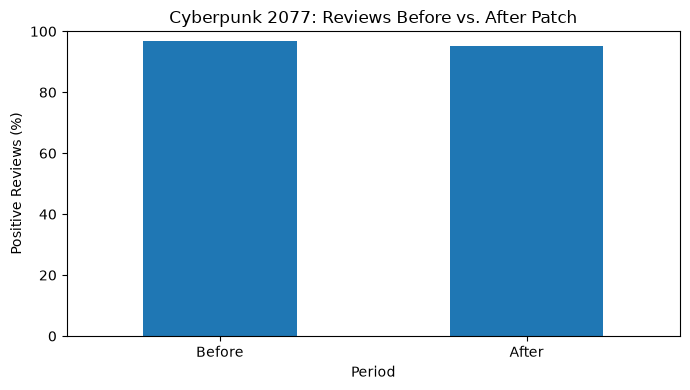

In [9]:
summary = summary.reindex(["Before", "After"])

summary["positive_percent"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title(f"{GAME}: Reviews Before vs. After Patch")
plt.ylabel("Positive Reviews (%)")
plt.xlabel("Period")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()